# 21 · Scaling: stacked fitting, sparse tables, query widths and a mechanism portfolio

Four tools for larger networks.  Each one gives the same answers as the
plain path, or says in advance what it cannot do:

1. **Stacked fitting** trains all neural mechanisms of one architecture as
   one batched network instead of one node at a time.  Same estimator, much
   less overhead per node.
2. **Sparse tables** store only the parent combinations that appear in the
   data.  Same probabilities as the dense table, memory `O(N)` instead of
   `O(K^(p+1))`.
3. **Query widths** tell, before running, whether an exact query fits a
   memory budget.  The router can use them to answer more queries exactly.
4. **A mechanism portfolio** picks one mechanism per node by successive
   halving on held-out data, without training every candidate to the end.

Ground truth (hidden from the learner), one per section:

    1. X_j = sin(1.5 s_j) + e_j,  s_j = sum of 1-2 parents / sqrt(#parents),
       e_j ~ 0.3 N(-1.5, 0.3^2) + 0.7 N(0.6, 0.4^2)        (skewed, bimodal noise)
    2. Y | P_1..P_p ~ softmax(sum_i w_i[P_i]),  K = 3 values,  w_i ~ N(0, 1)
    3. random discrete networks, K = 3, random tables (sparse and dense graphs)
    4. x ~ N(0, 1);  lin = 2x + N(0, 0.5^2);  bim = ±(1 + |x|/2) + N(0, 0.25^2);
       het = sin(2x) + (0.1 + 0.6·[x > 0]) N(0, 1)

- **NBN API:** `fit(method="stacked")`, `SparseCategoricalTableMechanism`, `TensorVariableElimination.plan_width` / `estimate_peak_bytes`, `HybridRouter(query_width_check=True)`, `nbn.learning.select_mechanisms`.
- **Runtime:** under 20 s on a laptop CPU.  Times are wall-clock and vary from run to run.
- **Install:** `pip install "nbn[examples]"`, then `jupyter lab examples/`.
- **Device:** CUDA or Apple MPS when available, else the CPU (set `NBN_EXAMPLES_DEVICE=cpu` to force the CPU).

In [1]:
import logging
import os
import time
import warnings

import matplotlib.pyplot as plt
import torch

from nbn import NeuralBayesianNetwork
from nbn.inference import HybridRouter, TensorVariableElimination
from nbn.learning import select_mechanisms
from nbn.mechanisms import (CategoricalTableMechanism, LinearGaussianMechanism, MDNMechanism,
                            SparseCategoricalTableMechanism)
from nbn.utils.device import resolve_device
from _figures import BLUE, ORANGE, AQUA, VERMILLION, MAGENTA, GREY, INK, DOUBLE, SINGLE, save, use_style

use_style()  # one style for every example: palette, sizes, fonts (_figures.py)
logging.getLogger("nbn").setLevel(logging.ERROR)     # the router logs every approximate answer

device = resolve_device(os.environ.get("NBN_EXAMPLES_DEVICE", "auto"))
print("device:", device)


def to_dev(d):
    return {k: v.to(device) for k, v in d.items()}

device: cpu


## 1. Stacked fitting: the same estimator, less overhead per node

`fit()` trains one node at a time.  For small neural mechanisms most of that
time is Python and kernel-launch overhead, paid once per node and per step.
`fit(method="stacked")` trains every mixture density network (MDN) of one
architecture together: the parameters of all nodes get a leading node axis,
and one step updates all of them.  Each node keeps its own loss, its own
Adam statistics and its own gradient clipping, so it is the same estimator;
only the order of the minibatches is shared across nodes.

Both runs below use the same mechanisms, the same 15 epochs, batch size and
learning rate.  Fit quality is the gap between the true and the fitted
log-likelihood on 2 000 test rows (nats per node; 0 is perfect).

In [2]:
NOISE_W, NOISE_MU, NOISE_SD = torch.tensor([0.3, 0.7]), torch.tensor([-1.5, 0.6]), torch.tensor([0.3, 0.4])


def chain_graph(n, seed=0):
    """Node j has 1-2 parents among the 3 nodes before it."""
    g = torch.Generator().manual_seed(seed)
    names = [f"X{i}" for i in range(n)]
    parents = {names[0]: []}
    for j in range(1, n):
        pool = list(range(max(0, j - 3), j))
        k = min(len(pool), 1 + int(torch.rand((), generator=g) < 0.6))
        parents[names[j]] = [names[pool[i]] for i in torch.randperm(len(pool), generator=g)[:k].tolist()]
    return names, parents


def simulate_chain(names, parents, n_rows, seed):
    g = torch.Generator().manual_seed(seed)
    x, true_lp = {}, torch.zeros(n_rows)
    for v in names:
        if not parents[v]:
            x[v] = torch.randn(n_rows, generator=g)
            true_lp += torch.distributions.Normal(0.0, 1.0).log_prob(x[v])
            continue
        s = sum(x[u] for u in parents[v]) / len(parents[v]) ** 0.5
        comp = (torch.rand(n_rows, generator=g) < NOISE_W[1]).long()
        e = NOISE_MU[comp] + NOISE_SD[comp] * torch.randn(n_rows, generator=g)
        x[v] = torch.sin(1.5 * s) + e
        r = (x[v] - torch.sin(1.5 * s)).unsqueeze(1)                   # exact noise density
        true_lp += torch.logsumexp(NOISE_W.log() + torch.distributions.Normal(NOISE_MU, NOISE_SD).log_prob(r), 1)
    return {k: v.unsqueeze(1) for k, v in x.items()}, true_lp


fit_rows = []
for n in (5, 10, 20, 40):
    names, parents = chain_graph(n)
    train, _ = simulate_chain(names, parents, 3000, seed=1)
    test, true_lp = simulate_chain(names, parents, 2000, seed=2)
    edges = [(u, v) for v in names for u in parents[v]]
    for method in ("local", "stacked"):
        model = NeuralBayesianNetwork(edges, variables=dict.fromkeys(names, ("continuous", 1)), device=device)
        for v in names:
            model.set_mechanism(v, MDNMechanism(num_components=3, hidden=(16,)))
        torch.manual_seed(0)
        t0 = time.perf_counter()
        model.fit(to_dev(train), method=method, epochs=15, batch_size=256, lr=3e-3, consolidate=False)
        seconds = time.perf_counter() - t0
        with torch.no_grad():
            fitted_lp = model.log_prob(to_dev(test)).cpu()
        gap = float((true_lp - fitted_lp).mean()) / n
        fit_rows.append(dict(n=n, method=method, seconds=seconds, gap=gap))
        print(f"{n:4d} nodes  {method:8s} {seconds:6.2f} s  ({1000 * seconds / n:5.1f} ms per node)"
              f"   log-likelihood gap to the truth {gap:.3f} nats per node")

   5 nodes  local      0.55 s  (109.1 ms per node)   log-likelihood gap to the truth 0.215 nats per node
   5 nodes  stacked    0.08 s  ( 16.2 ms per node)   log-likelihood gap to the truth 0.162 nats per node


  10 nodes  local      0.50 s  ( 49.7 ms per node)   log-likelihood gap to the truth 0.221 nats per node
  10 nodes  stacked    0.16 s  ( 16.2 ms per node)   log-likelihood gap to the truth 0.184 nats per node


  20 nodes  local      1.06 s  ( 52.8 ms per node)   log-likelihood gap to the truth 0.247 nats per node


  20 nodes  stacked    0.20 s  ( 10.1 ms per node)   log-likelihood gap to the truth 0.210 nats per node


  40 nodes  local      5.15 s  (128.7 ms per node)   log-likelihood gap to the truth 0.231 nats per node


  40 nodes  stacked    1.81 s  ( 45.3 ms per node)   log-likelihood gap to the truth 0.213 nats per node


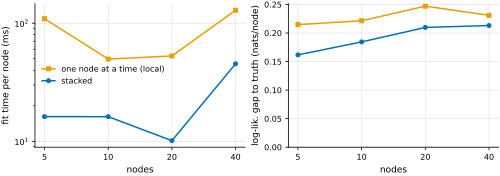

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(DOUBLE, 2.5))
for method, color, marker in (("local", ORANGE, "s"), ("stacked", BLUE, "o")):
    rows = [r for r in fit_rows if r["method"] == method]
    ns = [r["n"] for r in rows]
    label = "one node at a time (local)" if method == "local" else "stacked"
    axes[0].plot(ns, [1000 * r["seconds"] / r["n"] for r in rows], marker=marker, color=color, label=label)
    axes[1].plot(ns, [r["gap"] for r in rows], marker=marker, color=color, label=label)
axes[0].set(xscale="log", yscale="log", xlabel="nodes", ylabel="fit time per node (ms)")
axes[1].set(xscale="log", xlabel="nodes", ylabel="log-lik. gap to truth (nats/node)", ylim=(0, None))
axes[0].legend()
for ax in axes:
    ax.set_xticks([5, 10, 20, 40], labels=["5", "10", "20", "40"])
    ax.set_xticks([], minor=True)
save(fig, "21_stacked_fit")      # vector PDF + 300-dpi PNG in examples/figures/
plt.show()

**Figure.** Left: wall-clock fit time per node for the same 15 epochs, one node at a time (orange) and stacked (blue). Right: mean test log-likelihood of the truth minus that of the fitted network, per node (lower is better; 0 is the truth).

The stacked fit costs a fraction of the time per node.  The quality is the
same up to training noise: each run here uses one random start, and with
other starts the small difference between the two goes either way.  Stacking applies to MDN, neural categorical,
FlexCode and flow mechanisms; other mechanisms, root MDNs and
`warm_start=True` use the one-node-at-a-time path automatically.

## 2. Sparse tables: many parents without the exponential table

A table `P(Y | P_1..P_p)` with `K = 3` values has `3^(p+1)` entries.  With
`N` training rows at most `N` parent combinations are ever seen, and the
maximum-likelihood table is uniform on all the others.
`SparseCategoricalTableMechanism` stores only the seen rows plus one shared
uniform row.  It returns exactly the same probabilities as the dense
`CategoricalTableMechanism`.

The second question is statistical: *fast to fit* is not *well estimated*.
With many parents, most parent combinations of a new row were never seen
in training, and the fitted row there is uniform.

In [4]:
K, N_TRAIN = 3, 5000
W_TRUE = torch.randn(20, K, K, generator=torch.Generator().manual_seed(7))   # [parent i, its value, class]: additive logits


def simulate_star(p, n_rows, seed):
    g = torch.Generator().manual_seed(seed)
    pa = torch.randint(0, K, (n_rows, p), generator=g)
    probs = torch.softmax(sum(W_TRUE[i][pa[:, i]] for i in range(p)), -1)
    y = torch.multinomial(probs, 1, generator=g).squeeze(1)
    data = {f"P{i}": pa[:, i].float().unsqueeze(1) for i in range(p)}
    data["Y"] = y.float().unsqueeze(1)
    return data, probs


def star_model(p, table):
    parents = [f"P{i}" for i in range(p)]
    model = NeuralBayesianNetwork([(u, "Y") for u in parents],
                                  variables=dict.fromkeys(parents + ["Y"], ("discrete", K)), device=device)
    for u in parents:
        model.set_mechanism(u, CategoricalTableMechanism())
    model.set_mechanism("Y", table)
    return model


def stored_numbers(mech):
    return sum(t.numel() for t in list(mech.parameters()) + list(mech.buffers()) if t is not None)


sparse_rows = []
with warnings.catch_warnings():
    warnings.simplefilter("ignore")                   # the dense table warns about its own size
    for p in (2, 4, 6, 8, 10, 12, 14, 16, 18, 20):
        train, _ = simulate_star(p, N_TRAIN, seed=1)
        test, true_probs = simulate_star(p, 2000, seed=2)
        sparse = star_model(p, SparseCategoricalTableMechanism())
        sparse.fit(to_dev(train))
        mech = sparse.mechanisms["Y"]
        parents_test = torch.cat([test[f"P{i}"] for i in range(p)], 1).to(device)
        with torch.no_grad():
            fitted = torch.stack([mech.log_prob(torch.full((2000, 1), float(c), device=device), parents_test)
                                  for c in range(K)], 1).exp().cpu()
        row = dict(p=p, sparse=stored_numbers(mech), dense=2 * K ** (p + 1), dense_fitted=False,
                   tv=float(0.5 * (fitted - true_probs).abs().sum(1).mean()))
        seen = {tuple(r) for r in torch.cat([train[f"P{i}"] for i in range(p)], 1).long().tolist()}
        row["unseen"] = sum(tuple(r) not in seen for r in parents_test.long().cpu().tolist()) / 2000
        if p <= 12:                                   # the dense table still fits comfortably
            dense = star_model(p, CategoricalTableMechanism())
            dense.fit(to_dev(train))
            with torch.no_grad():
                same = torch.equal(dense.log_prob(to_dev(test), per_node=True)["Y"],
                                   sparse.log_prob(to_dev(test), per_node=True)["Y"])
            row.update(dense=stored_numbers(dense.mechanisms["Y"]), dense_fitted=True, identical=same)
        sparse_rows.append(row)
        print(f"p = {p:2d} parents: dense {row['dense']:>13,} numbers"
              f"{'' if row['dense_fitted'] else ' (would need)':13s}  sparse {row['sparse']:>7,}"
              f"   identical log_prob: {row.get('identical', '-')!s:5s}"
              f"   unseen test rows {row['unseen']:5.1%}   TV error {row['tv']:.3f}")

p =  2 parents: dense            54 numbers               sparse      66   identical log_prob: True    unseen test rows  0.0%   TV error 0.017
p =  4 parents: dense           486 numbers               sparse     570   identical log_prob: True    unseen test rows  0.0%   TV error 0.056
p =  6 parents: dense         4,374 numbers               sparse   5,092   identical log_prob: True    unseen test rows  0.2%   TV error 0.150
p =  8 parents: dense        39,366 numbers               sparse  24,713   identical log_prob: True    unseen test rows 47.9%   TV error 0.360
p = 10 parents: dense       354,294 numbers               sparse  33,561   identical log_prob: True    unseen test rows 91.2%   TV error 0.462
p = 12 parents: dense     3,188,646 numbers               sparse  34,800   identical log_prob: True    unseen test rows 99.0%   TV error 0.496
p = 14 parents: dense    28,697,814 numbers (would need)  sparse  34,968   identical log_prob: -       unseen test rows 99.9%   TV error 0.496

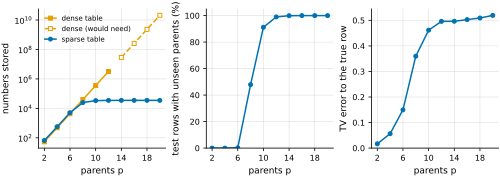

In [5]:
ps = [r["p"] for r in sparse_rows]
fitted_dense = [r for r in sparse_rows if r["dense_fitted"]]
computed_dense = [r for r in sparse_rows if not r["dense_fitted"]]
fig, axes = plt.subplots(1, 3, figsize=(DOUBLE, 2.4))
axes[0].plot([r["p"] for r in fitted_dense], [r["dense"] for r in fitted_dense], "s-", color=ORANGE, label="dense table")
axes[0].plot([r["p"] for r in computed_dense], [r["dense"] for r in computed_dense], "s--", color=ORANGE,
             mfc="white", label="dense (would need)")
axes[0].plot(ps, [r["sparse"] for r in sparse_rows], "o-", color=BLUE, label="sparse table")
axes[0].set(yscale="log", xlabel="parents p", ylabel="numbers stored")
axes[0].legend(fontsize=7)
axes[1].plot(ps, [100 * r["unseen"] for r in sparse_rows], "o-", color=BLUE)
axes[1].set(xlabel="parents p", ylabel="test rows with unseen parents (%)", ylim=(0, 105))
axes[2].plot(ps, [r["tv"] for r in sparse_rows], "o-", color=BLUE)
axes[2].set(xlabel="parents p", ylabel="TV error to the true row", ylim=(0, None))
for ax in axes:
    ax.set_xticks([2, 6, 10, 14, 18])
save(fig, "21_sparse_tables")      # vector PDF + 300-dpi PNG in examples/figures/
plt.show()

**Figure.** A child with `p` parents, `K = 3`, 5 000 training rows. Left: numbers stored by the dense table (orange; hollow: `2·3^(p+1)`, too large to build here) and by the sparse table (blue), log scale. Middle: share of 2 000 test rows whose parent combination never appears in training. Right: mean total-variation distance between the fitted row and the true row on the test rows (0 = exact, 1 = disjoint).

The sparse table removes the memory wall: its size stays near the number of
training rows at any in-degree, with identical `log_prob`.  It does not
remove the statistical wall.  From 8 parents on, about half or more of the
test rows fall in a parent combination never seen in training, where the
fitted row is uniform, and the error grows.  There,
a model that shares strength across rows (an additive or neural CPD such as
`NeuralCategoricalMechanism`) is needed; that is a modelling choice.

## 3. Will an exact query fit?  Ask for its width first

Exact variable elimination builds tables over `w + 1` variables, where `w`
is the induced width of the query's elimination plan.  With `K = 3` values
the largest table has about `3^(w+1)` entries.  The width depends on the
query, not only on the network: NBN removes the nodes that cannot matter
(barren nodes, observed nodes) before planning.

`TensorVariableElimination.plan_width` returns that width and
`estimate_peak_bytes` the memory the plan needs.  Both run before any
computation.  Below: 20 random queries `P(target | 4 observed nodes)` on
an 80-node *sparse* network (parents among the 4 previous nodes) and an
80-node *dense* one (parents anywhere), with a 256 MiB budget.

In [6]:
def random_discrete_network(n, window, seed, n_rows=3000, max_parents=6):
    """Random DAG (parents among the `window` previous nodes, or anywhere if None), random tables, fitted."""
    g = torch.Generator().manual_seed(seed)
    names = [f"V{i}" for i in range(n)]
    parents = {}
    for j, v in enumerate(names):
        pool = list(range(max(0, j - window), j)) if window else list(range(j))
        k = min(len(pool), max_parents, int(torch.poisson(torch.tensor(3.0), generator=g)))
        parents[v] = [names[pool[i]] for i in torch.randperm(len(pool), generator=g)[:k].tolist()]
    x = {}
    for v in names:
        table = torch.randn(K ** len(parents[v]), K, generator=g) * 1.5
        idx = torch.zeros(n_rows, dtype=torch.long)
        for u in parents[v]:
            idx = idx * K + x[u]
        x[v] = torch.multinomial(torch.softmax(table[idx], -1), 1, generator=g).squeeze(1)
    model = NeuralBayesianNetwork([(u, v) for v in names for u in parents[v]],
                                  variables=dict.fromkeys(names, ("discrete", K)), device=device)
    model.auto_mechanisms()
    model.fit(to_dev({k: v.float() for k, v in x.items()}))
    return model, names


def random_queries(names, n_queries, seed):
    g = torch.Generator().manual_seed(seed)
    out = []
    for _ in range(n_queries):
        perm = torch.randperm(len(names), generator=g).tolist()
        out.append((names[perm[0]], {names[i]: torch.tensor(1, device=device) for i in perm[1:5]}))
    return out


BUDGET = 256 * 2**20
probe = TensorVariableElimination()
width_rows = {}
for family, window in (("sparse", 4), ("dense", None)):
    model, names = random_discrete_network(80, window, seed=0)
    exact_ve = TensorVariableElimination(memory_budget=BUDGET)
    rows = []
    for target, evidence in random_queries(names, 20, seed=1):
        width = probe.plan_width(model, target, tuple(evidence))
        peak = probe.estimate_peak_bytes(model, target, tuple(evidence))
        t0 = time.perf_counter()
        try:
            model.query([target], evidence=evidence, engine=exact_ve)
            answered = True
        except RuntimeError:                      # out of the memory budget: refused before computing
            answered = False
        rows.append(dict(width=width, peak=peak, predicted=peak <= BUDGET, answered=answered,
                         seconds=time.perf_counter() - t0))
    width_rows[family] = (model, names, rows)
    agree = sum(r["predicted"] == r["answered"] for r in rows)
    print(f"{family:6s}: network width {model.dag.induced_width():2d} | query widths "
          f"{min(r['width'] for r in rows)}-{max(r['width'] for r in rows)} | answered exactly "
          f"{sum(r['answered'] for r in rows):2d}/20 | prediction from estimate_peak_bytes right "
          f"for {agree}/20 | slowest answered query {max(r['seconds'] for r in rows if r['answered']):.2f} s")

sparse: network width  4 | query widths 4-5 | answered exactly 20/20 | prediction from estimate_peak_bytes right for 20/20 | slowest answered query 0.01 s


dense : network width 27 | query widths 0-23 | answered exactly 10/20 | prediction from estimate_peak_bytes right for 20/20 | slowest answered query 0.11 s


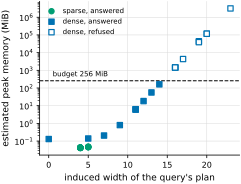

In [7]:
fig, ax = plt.subplots(figsize=(SINGLE, 2.6))
for family, color, marker in (("sparse", AQUA, "o"), ("dense", BLUE, "s")):
    rows = width_rows[family][2]
    for answered in (True, False):
        sel = [r for r in rows if r["answered"] == answered]
        if sel:
            ax.scatter([r["width"] for r in sel], [max(r["peak"], 1) / 2**20 for r in sel], marker=marker,
                       s=28, color=color if answered else "white", edgecolors=color, linewidths=1.2,
                       label=f"{family}, {'answered' if answered else 'refused'}", zorder=3)
ax.axhline(BUDGET / 2**20, color=INK, ls="--", lw=1)
ax.text(0.5, BUDGET / 2**20 * 1.8, "budget 256 MiB", fontsize=7)
ax.set(yscale="log", xlabel="induced width of the query's plan", ylabel="estimated peak memory (MiB)")
ax.legend(fontsize=7, loc="upper left")
save(fig, "21_query_widths")      # vector PDF + 300-dpi PNG in examples/figures/
plt.show()

**Figure.** Each marker is one query `P(target | 4 observed nodes)` on an 80-node network: the induced width of its elimination plan and the peak memory that plan needs, estimated before running (log scale). Filled: answered exactly within the 256 MiB budget; hollow: refused by the budget. Dashed line: the budget.

The memory grows about 3× per unit of width (`K = 3`).  On the sparse
network every query is small.  On the dense one the widths spread widely,
and the estimate tells in advance which queries exact elimination can
answer.  The optimal width is NP-hard to find [Koller & Friedman 2009,
Thm 9.7]: NBN's greedy min-fill plan gives an upper bound.

### The router: look at the query, not only at the network

`HybridRouter` sends a query to likelihood weighting (approximate) when the
width of the *whole network* is above `treewidth_threshold` (default 25).
With `query_width_check=True` (opt-in) it then measures the width of the
query's own plan, and answers exactly when that plan is narrow and fits
memory (here the same 256 MiB budget).

In [8]:
model, names, _ = width_rows["dense"]
print(f"whole dense network: induced width {model.dag.induced_width()} (threshold 25)")
for check in (False, True):
    router = HybridRouter(query_width_check=check, memory_budget=BUDGET)
    engines = []
    for target, evidence in random_queries(names, 20, seed=1):
        router.query(model, [target], evidence)
        engines.append(router.last_engine)
    print(f"query_width_check={check!s:5s}: exact {engines.count('tensor_ve'):2d}/20, "
          f"likelihood weighting {engines.count('likelihood_weighting'):2d}/20")

whole dense network: induced width 27 (threshold 25)
query_width_check=False: exact  0/20, likelihood weighting 20/20


query_width_check=True : exact 10/20, likelihood weighting 10/20


The default keeps the historical routing.  With the check on, more queries
are answered exactly; some of them can be slower than sampling.

## 4. A mechanism portfolio: one mechanism per node, chosen on held-out data

Which mechanism should each node use?  Training every candidate to the end
costs the sum of all their budgets.  `select_mechanisms` uses successive
halving (the subroutine of Hyperband: Li et al., *JMLR* 18, 2018): train
every candidate briefly, score it on held-out rows, keep the best third,
train the survivors three times longer, and repeat.  The held-out
log-likelihood of a network is a sum of one term per node, so each node
can choose on its own [Koller & Friedman 2009, Prop. 17.1].

Three children of one parent `x`, each needing something different:
`lin` is linear-Gaussian, `bim` is bimodal, `het` has noise that changes
with `x`.  Six candidates per node.

In [9]:
def simulate_portfolio(n_rows, seed):
    g = torch.Generator().manual_seed(seed)
    x = torch.randn(n_rows, generator=g)
    lin = 2 * x + 0.5 * torch.randn(n_rows, generator=g)
    sign = torch.where(torch.rand(n_rows, generator=g) < 0.5, -1.0, 1.0)
    bim = sign * (1.0 + 0.5 * x.abs()) + 0.25 * torch.randn(n_rows, generator=g)
    het = torch.sin(2 * x) + (0.1 + 0.6 * (x > 0).float()) * torch.randn(n_rows, generator=g)
    return {k: v.unsqueeze(1) for k, v in dict(x=x, lin=lin, bim=bim, het=het).items()}


CANDIDATES = {
    "linear-Gaussian": LinearGaussianMechanism,
    "MDN 1 comp.": lambda: MDNMechanism(num_components=1, hidden=(32,)),
    "MDN 3 comp.": lambda: MDNMechanism(num_components=3, hidden=(32,)),
    "MDN 5 comp.": lambda: MDNMechanism(num_components=5, hidden=(32,)),
    "MDN 1 comp., wide": lambda: MDNMechanism(num_components=1, hidden=(64, 64)),
    "MDN 3 comp., wide": lambda: MDNMechanism(num_components=3, hidden=(64, 64)),
}
CHILDREN, MAX_EPOCHS, FIT = ["lin", "bim", "het"], 54, dict(batch_size=256, lr=3e-3)
data = simulate_portfolio(5000, seed=1)       # selection data: split into train / validation inside
test = simulate_portfolio(5000, seed=2)       # a separate test set, never seen by the selection

model = NeuralBayesianNetwork([("x", c) for c in CHILDREN], variables=dict.fromkeys(data, ("continuous", 1)),
                              device=device)
model.set_mechanism("x", LinearGaussianMechanism())                 # the root: a standard normal
model.mechanisms["x"].fit_local(data["x"].to(device), None)
torch.manual_seed(0)
t0 = time.perf_counter()
report = select_mechanisms(model, to_dev(data), CANDIDATES, nodes=CHILDREN, min_epochs=5,
                           max_epochs=MAX_EPOCHS, eta=3, seed=0, **FIT)
select_seconds = time.perf_counter() - t0
print(report.summary())
print(f"selection: {select_seconds:.1f} s in total")
print(f"rows: {len(report.train_index)} for training, {len(report.val_index)} for selection, "
      f"overlap: {bool(torch.isin(report.train_index, report.val_index).any())}")

lin: linear-Gaussian (42 candidate-epochs vs 270 to train all to the end; 0.31s)
bim: MDN 3 comp., wide (90 candidate-epochs vs 270 to train all to the end; 0.61s)
het: MDN 3 comp., wide (90 candidate-epochs vs 270 to train all to the end; 0.63s)
selection: 1.6 s in total
rows: 4000 for training, 1000 for selection, overlap: False


For comparison, train every candidate to the end (54 epochs) on the same
training rows, and score everything on the separate test set.  The
validation score of the winner is optimistic (it won on those rows), so the
fair final score is the test one.

In [10]:
train_rows = {k: v[report.train_index] for k, v in data.items()}
test_ll, t0 = {c: {} for c in CHILDREN}, time.perf_counter()
for child in CHILDREN:
    for name, factory in CANDIDATES.items():
        mech = factory()
        kwargs = {} if isinstance(mech, LinearGaussianMechanism) else dict(epochs=MAX_EPOCHS, **FIT)
        torch.manual_seed(0)
        mech.fit_local(train_rows[child].to(device), train_rows["x"].to(device), **kwargs)
        with torch.no_grad():
            test_ll[child][name] = float(mech.log_prob(test[child].to(device), test["x"].to(device)).mean())
full_seconds = time.perf_counter() - t0
with torch.no_grad():
    chosen_ll = {c: float(model.log_prob(to_dev(test), per_node=True)[c].mean()) for c in CHILDREN}
print(f"train every candidate to the end: {full_seconds:.1f} s | portfolio: {select_seconds:.1f} s")
for c in CHILDREN:
    best = max(test_ll[c], key=test_ll[c].get)
    print(f"{c:4s} chosen {report.chosen[c]:18s} test log-lik {chosen_ll[c]:7.3f} | best fully trained "
          f"{best:18s} {test_ll[c][best]:7.3f} | chosen minus best {chosen_ll[c] - test_ll[c][best]:+.3f} nats")

train every candidate to the end: 4.4 s | portfolio: 1.6 s
lin  chosen linear-Gaussian    test log-lik  -0.707 | best fully trained linear-Gaussian     -0.707 | chosen minus best +0.000 nats
bim  chosen MDN 3 comp., wide  test log-lik  -0.754 | best fully trained MDN 3 comp.         -0.729 | chosen minus best -0.024 nats
het  chosen MDN 3 comp., wide  test log-lik  -0.113 | best fully trained MDN 1 comp., wide   -0.129 | chosen minus best +0.017 nats


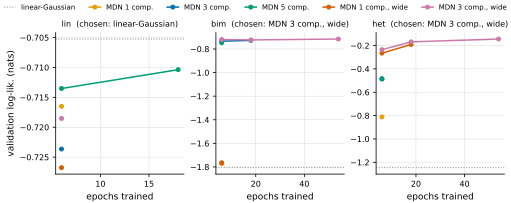

In [11]:
COLORS = dict(zip(CANDIDATES, (GREY, ORANGE, BLUE, AQUA, VERMILLION, MAGENTA)))
fig, axes = plt.subplots(1, 3, figsize=(DOUBLE, 2.6))
for ax, child in zip(axes, CHILDREN):
    by_cand = {}
    for name, epochs, score in report.rungs[child]:
        by_cand.setdefault(name, []).append((epochs, score))
    for name, pts in by_cand.items():
        if name == "linear-Gaussian":                         # closed form: one score, no epochs
            ax.axhline(pts[0][1], color=COLORS[name], lw=1, ls=":", label=name)
        else:
            ax.plot([e for e, _ in pts], [s for _, s in pts], "o-", color=COLORS[name], ms=4, label=name)
    ax.set(title=f"{child}  (chosen: {report.chosen[child]})", xlabel="epochs trained")
    ax.title.set_fontsize(8)
axes[0].set_ylabel("validation log-lik. (nats)")
handles, labels = axes[1].get_legend_handles_labels()
fig.legend(handles, labels, loc="lower center", bbox_to_anchor=(0.5, 1.0), ncol=6, fontsize=7)
save(fig, "21_portfolio_rungs")      # vector PDF + 300-dpi PNG in examples/figures/
plt.show()

**Figure.** Successive halving per node: the validation log-likelihood of each candidate at each rung (markers) against the epochs it has been trained so far. A line stops where its candidate was dropped. The linear-Gaussian candidate is fitted in closed form, so it has one score (dotted line).

Most candidates are dropped after a few epochs; only the survivor is
trained to the end.  `report.epochs_spent` against `report.epochs_full`
counts the saving in candidate-epochs.

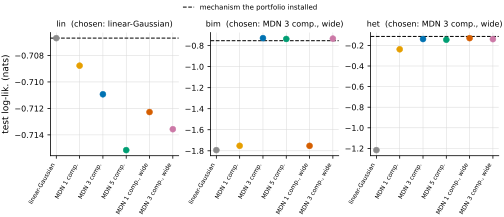

{'lin': '42 of 270 candidate-epochs', 'bim': '90 of 270 candidate-epochs', 'het': '90 of 270 candidate-epochs'}


In [12]:
x = torch.arange(len(CANDIDATES))
fig, axes = plt.subplots(1, 3, figsize=(DOUBLE, 2.8))
for ax, child in zip(axes, CHILDREN):
    vals = [test_ll[child][n] for n in CANDIDATES]
    ax.scatter(x, vals, color=[COLORS[n] for n in CANDIDATES], s=36, zorder=3)
    ax.axhline(chosen_ll[child], color=INK, ls="--", lw=1, label="mechanism the portfolio installed")
    ax.set(title=f"{child}  (chosen: {report.chosen[child]})", xticks=x)
    ax.set_xticklabels(list(CANDIDATES), rotation=60, ha="right", fontsize=6)
    ax.title.set_fontsize(8)
axes[0].set_ylabel("test log-lik. (nats)")
handles, labels = axes[0].get_legend_handles_labels()
fig.legend(handles, labels, loc="lower center", bbox_to_anchor=(0.5, 1.0), fontsize=7)
save(fig, "21_portfolio_test")      # vector PDF + 300-dpi PNG in examples/figures/
plt.show()
print({c: f"{report.epochs_spent[c]} of {report.epochs_full[c]} candidate-epochs" for c in CHILDREN})

**Figure.** Mean log-likelihood on the separate test set (higher is better) of every candidate trained for the full 54 epochs (dots), and of the mechanism the portfolio installed (dashed line), per node.

The portfolio picks a linear-Gaussian model where the truth is linear and a
mixture where it is bimodal or heteroscedastic.  Its choice is within a few
hundredths of a nat of the best fully trained candidate (the two are trained
from different random starts, so differences of that size are training
noise), for a fraction of the candidate-epochs.  Two cautions:

* successive halving ranks candidates by their *early* scores, so a
  candidate that learns slowly but ends best can be dropped (`min_epochs`
  sets how early the first cut is);
* `report.train_index` and `report.val_index` are the rows used to fit and
  to select.  Calibration and PAC tools that need held-out rows must not
  reuse them: pass them as `fit_ids` to the calibration builders
  (`nbn.scm.check_held_out`).